# Two-Stage NH₃/H₂ Staged Combustion — PSR Sweep

This notebook models:

**NH₃/H₂ fuel + primary air → Primary PSR → add secondary air → Secondary PSR → final exhaust**

Initial parameter space:

- NH₃ fraction: 0–100% in 10% increments
- Primary equivalence ratio, φ₁: 1.0–2.0 in 0.1 increments
- Residence time: 20–100 ms
- Overall equivalence ratio: fixed at 0.9

Total cases:

\[
11 x 11 x 5=605
\]

The analysis section reports the quantities shown in the reference
presentation: temperature, H₂, NH₃, NO, NO₂ and N₂O at both PSR outlets.
It also reports NOx, NH₃ slip and H₂ slip.


## 1. Imports

In [1]:
import time
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cantera as ct

print("Cantera version:", ct.__version__)


Cantera version: 3.0.0


## 2. Model settings

These values are fixed in the initial study. Fuel composition, primary φ, and residence time are varied later.

The NH₃/H₂ composition is specified on a mole basis.


In [2]:
# Mechanism
MECH = "mechanisms/TamaokiNH3.yaml"

# Inlet conditions
T_IN = 300.0          # K
P_IN = ct.one_atm     # Pa

# Fixed overall equivalence ratio
PHI_OVERALL = 0.9

# Air composition
AIR = {"O2": 1.0, "N2": 3.76}

print("Mechanism:", MECH)
print("Inlet temperature:", T_IN, "K")
print("Inlet pressure:", P_IN / ct.one_atm, "atm")
print("Overall phi:", PHI_OVERALL)


Mechanism: TamaokiNH3.yaml
Inlet temperature: 300.0 K
Inlet pressure: 1.0 atm
Overall phi: 0.9


## 3. Calculate primary and secondary air

Use a basis of **1 mole of total fuel**.


In [ ]:
def calculate_air_amounts(x_nh3, phi_1):
    # H2 fraction
    x_h2 = 1.0 - x_nh3

    # Stoichiometric O2 for 1 mole total fuel
    n_O2_stoic = (
        0.75 * x_nh3
        + 0.50 * x_h2
    )

    # Stoichiometric air
    n_air_stoic = 4.76 * n_O2_stoic

    # Air in primary zone
    n_air_1 = n_air_stoic / phi_1

    # Total air required for overall phi = 0.9
    n_air_total = n_air_stoic / PHI_OVERALL

    # Remaining air goes to secondary zone
    n_air_2 = n_air_total - n_air_1

    return n_air_stoic, n_air_1, n_air_2


# Simple check
n_air_stoic, n_air_1, n_air_2 = calculate_air_amounts(
    x_nh3=0.50,
    phi_1=1.50
)

print(f"Stoichiometric air = {n_air_stoic:.4f} mol")
print(f"Primary air        = {n_air_1:.4f} mol")
print(f"Secondary air      = {n_air_2:.4f} mol")


Stoichiometric air = 2.9750 mol
Primary air        = 1.9833 mol
Secondary air      = 1.3222 mol


## 4. Simulate one two-stage case

Each case is defined by:

- `x_nh3` — NH₃ mole fraction in the fuel
- `phi_1` — primary-zone equivalence ratio
- `tau` — residence time in seconds

For the initial study:

\[
tau_1=tau_2=tau
\]

The primary reactor is solved first. Its products are then mixed with the calculated secondary air and sent to the secondary reactor.


In [ ]:
def integrate_to_steady_state(sim, reactor, tau,
                              min_residence_times=5.0,
                              max_residence_times=100.0,
                              tolerance=1e-8):
    """
    Integrate a PSR until its temperature and species composition stop changing.
    consider steady state to be reached when the relative change in temperature and species mole fractions is below a specified tolerance for a minimum number of residence times, but integration will stop if the maximum number of residence times is exceeded.
    This is used instead of ReactorNet.solve_steady()
    """
    t = sim.time
    previous_T = reactor.T
    previous_Y = reactor.thermo.Y.copy()

    minimum_time = t + min_residence_times * tau
    maximum_time = t + max_residence_times * tau

    while t < maximum_time:
        t_next = min(t + tau, maximum_time)
        sim.advance(t_next)
        t = sim.time

        current_T = reactor.T
        current_Y = reactor.thermo.Y

        T_change = abs(current_T - previous_T) / max(abs(current_T), 1.0)
        Y_change = np.max(
            np.abs(current_Y - previous_Y)
            / np.maximum(np.abs(current_Y), 1e-30)
        )

        if t >= minimum_time and T_change < tolerance and Y_change < tolerance:
            return True, t

        previous_T = current_T
        previous_Y = current_Y.copy()

    return False, t


TRACKED_SPECIES = ["NH3", "H2", "NO", "NO2", "N2O"]


def get_species_mole_fractions(gas, species_list=TRACKED_SPECIES):
    """Return requested species mole fractions; use zero if absent."""
    return {
        species: (
            gas[species].X[0]
            if species in gas.species_names
            else 0.0
        )
        for species in species_list
    }


def simulate_case(params):
    """
    Simulate one two-stage NH3/H2 combustion case.

    params = (NH3 mole fraction, primary equivalence ratio, residence time)
    """

    x_nh3, phi_1, tau = params
    x_h2 = 1.0 - x_nh3

    try:
        # =====================================================
        # 1. AIR CALCULATION
        # =====================================================
        n_air_stoic, n_air_1, n_air_2 = calculate_air_amounts(
            x_nh3, phi_1
        )

        if n_air_2 < 0:
            raise ValueError("Secondary air is negative.")

        # =====================================================
        # 2. FUEL COMPOSITION
        # =====================================================
        fuel = {}

        if x_nh3 > 0:
            fuel["NH3"] = x_nh3

        if x_h2 > 0:
            fuel["H2"] = x_h2

        # =====================================================
        # 3. LOAD MECHANISM
        # =====================================================
        gas = ct.Solution(MECH)

        # =====================================================
        # 4. PRIMARY PSR
        # =====================================================
        fuel_stream = ct.Quantity(gas, constant="HP")
        fuel_stream.TPX = T_IN, P_IN, fuel
        fuel_stream.moles = 1.0

        air_stream_1 = ct.Quantity(gas, constant="HP") # cantera quantity object, with constant enthalpy and pressure
        air_stream_1.TPX = T_IN, P_IN, AIR
        air_stream_1.moles = n_air_1

        primary_mix = fuel_stream + air_stream_1

        gas1 = ct.Solution(MECH)
        gas1.TPX = primary_mix.phase.TPX
        gas1.equilibrate("HP")

        reactor1 = ct.IdealGasReactor(gas1, energy="on")
        reactor1.volume = 1.0

        inlet1 = ct.Reservoir(primary_mix.phase)
        exhaust1 = ct.Reservoir(gas1)

        mfc1 = ct.MassFlowController(
            inlet1,
            reactor1,
            mdot=lambda t: reactor1.mass / tau
        )

        pc1 = ct.PressureController(
            reactor1,
            exhaust1,
            primary=mfc1,
            K=0.01
        )

        sim1 = ct.ReactorNet([reactor1])

        converged1, integration_time_1 = integrate_to_steady_state(
            sim1, reactor1, tau
        )

        if not converged1:
            raise RuntimeError(
                "Primary PSR did not reach steady state within "
                "30 residence times."
            )

        # Primary outlet quantities.
        primary_gas = reactor1.thermo
        primary_X = get_species_mole_fractions(primary_gas)
        T_primary = reactor1.T

        # Transfer the actual primary-reactor outlet state to Stage 2.
        primary_outlet_gas = ct.Solution(MECH) 
        # copy the state of the converged primary reactor to a new gas object for the secondary reactor
        primary_outlet_gas.TDY = reactor1.thermo.TDY  # TDY- temperature, density, composition

        primary_products = ct.Quantity(
            primary_outlet_gas,
            constant="HP"
        )
        primary_products.moles = primary_mix.moles # amount of product stream = amount of moles we started with

        # =====================================================
        # 5. SECONDARY / FINAL PSR
        # =====================================================
        air_stream_2 = ct.Quantity(gas, constant="HP")
        air_stream_2.TPX = T_IN, P_IN, AIR
        air_stream_2.moles = n_air_2

        secondary_mix = primary_products + air_stream_2

        overall_phi = n_air_stoic / (n_air_1 + n_air_2)

        gas2 = ct.Solution(MECH)
        gas2.TPX = secondary_mix.phase.TPX

        reactor2 = ct.IdealGasReactor(gas2, energy="on")
        reactor2.volume = 1.0

        inlet2 = ct.Reservoir(secondary_mix.phase)
        exhaust2 = ct.Reservoir(gas2)

        mfc2 = ct.MassFlowController(     # mass flow controller for the secondary reactor
            inlet2,
            reactor2,
            mdot=lambda t: reactor2.mass / tau   #at any simulation time t, the mass flow rate is equal to the mass of the reactor divided by the residence time tau
        )

        pc2 = ct.PressureController(   # pressure controller for the secondary reactor
            reactor2,
            exhaust2,
            primary=mfc2,   # the primary argument specifies that the pressure controller should use the mass flow controller mfc2 to control the flow of gas into the reactor
            K=0.01         # the K argument specifies the proportional gain for the pressure controller, which determines how aggressively it responds to changes in pressure [m(dot)out = m(dot)primary + K*(P(reactor) - P(dowstream))]
        )

        sim2 = ct.ReactorNet([reactor2])    #numerical simulation system that solves its equations

        converged2, integration_time_2 = integrate_to_steady_state(
            sim2, reactor2, tau
        )  # converged2 is a boolean indicating whether the secondary PSR reached steady state within the specified number of residence times, and integration_time_2 is the total time taken for the integration to reach steady state.

        if not converged2:
            raise RuntimeError(
                "Secondary PSR did not reach steady state within "
                f"{tau} residence times."
            )

        # Final outlet quantities.
        final_gas = reactor2.thermo
        final_X = get_species_mole_fractions(final_gas)

        # =====================================================
        # 6. DERIVED RESULTS
        # =====================================================
        NOx_primary_ppm = (primary_X["NO"] + primary_X["NO2"]) * 1e6
        NOx_final_ppm = (final_X["NO"] + final_X["NO2"]) * 1e6

        # Retain the original notebook's preliminary conversion diagnostic.
        if x_nh3 > 0:
            NH3_conversion = (
                1.0 - final_X["NH3"] * secondary_mix.moles / x_nh3
            ) * 100.0
        else:
            NH3_conversion = np.nan

        if x_h2 > 0:
            H2_conversion = (
                1.0 - final_X["H2"] * secondary_mix.moles / x_h2
            ) * 100.0
        else:
            H2_conversion = np.nan

        return {
            # Operating conditions
            "NH3_frac": x_nh3,
            "H2_frac": x_h2,
            "Phi_1": phi_1,
            "Phi_overall": overall_phi,
            "Tau_ms": tau * 1000.0,

            # Air split
            "Air_stoic": n_air_stoic,
            "Air_primary": n_air_1,
            "Air_secondary": n_air_2,
            "Air_total": n_air_1 + n_air_2,

            # Temperatures
            "T_primary_K": T_primary,
            "T_final_K": reactor2.T,

            # Primary PSR mole fractions
            "X_NH3_primary": primary_X["NH3"],
            "X_H2_primary": primary_X["H2"],
            "X_NO_primary": primary_X["NO"],
            "X_NO2_primary": primary_X["NO2"],
            "X_N2O_primary": primary_X["N2O"],

            # Final PSR mole fractions
            "X_NH3_final": final_X["NH3"],
            "X_H2_final": final_X["H2"],
            "X_NO_final": final_X["NO"],
            "X_NO2_final": final_X["NO2"],
            "X_N2O_final": final_X["N2O"],

            # Primary stage in ppm
            "NO_primary_ppm": primary_X["NO"] * 1e6,
            "NO2_primary_ppm": primary_X["NO2"] * 1e6,
            "NOx_primary_ppm": NOx_primary_ppm,
            "N2O_primary_ppm": primary_X["N2O"] * 1e6,
            "NH3_primary_slip_ppm": primary_X["NH3"] * 1e6,
            "H2_primary_slip_ppm": primary_X["H2"] * 1e6,

            # Final stage in ppm
            "NO_ppm": final_X["NO"] * 1e6,
            "NO2_ppm": final_X["NO2"] * 1e6,
            "NOx_ppm": NOx_final_ppm,
            "N2O_ppm": final_X["N2O"] * 1e6,
            "NH3_slip_ppm": final_X["NH3"] * 1e6,
            "H2_slip_ppm": final_X["H2"] * 1e6,

            # Preliminary conversion diagnostics
            "NH3_conversion": NH3_conversion,
            "H2_conversion": H2_conversion,

            # Numerical information
            "Primary_integration_s": integration_time_1,
            "Secondary_integration_s": integration_time_2,

            "Status": "Converged"
        }

    except Exception as e:
        return {
            "NH3_frac": x_nh3,
            "H2_frac": x_h2,
            "Phi_1": phi_1,
            "Phi_overall": np.nan,
            "Tau_ms": tau * 1000.0,
            "Status": f"FAILED: {type(e).__name__}: {e}"
        }


## 5. Test ONE complete two-stage case

**Run this test before starting the 605-case sweep.**

Test conditions:

- Fuel = 50% NH₃ + 50% H₂
- Primary equivalence ratio φ₁ = 1.5
- Residence time = 60 ms in each PSR
- Overall equivalence ratio = 0.9

### Cantera 3.0.0 compatibility

This notebook uses:

```python
reactor.thermo
```

to access the gas state stored inside an `IdealGasReactor`.

It does **not** use `reactor.phase` and it does **not** call `ReactorNet.solve_steady()`.

If a case fails, the complete Python traceback is printed so that the exact failing line is visible.


In [48]:
# One complete two-stage test case.
# Do not start the 605-case sweep until this succeeds.

test_case = (
    0.50,   # NH3 fraction in fuel
    1.50,   # Primary equivalence ratio
    0.060   # Residence time [s] = 60 ms
)

print("Running one complete two-stage case...")
result = simulate_case(test_case)

pd.Series(result)


Running one complete two-stage case...


NH3_frac                            0.5
H2_frac                             0.5
Phi_1                               1.5
Phi_overall                         0.9
Tau_ms                             60.0
Air_stoic                         2.975
Air_primary                    1.983333
Air_secondary                  1.322222
Air_total                      3.305556
T_primary_K                 1942.109022
T_final_K                   2088.803151
X_NH3_primary                  0.002063
X_H2_primary                   0.133057
X_NO_primary                   0.000234
X_NO2_primary                       0.0
X_N2O_primary                  0.000009
X_NH3_final                         0.0
X_H2_final                     0.002224
X_NO_final                     0.001415
X_NO2_final                         0.0
X_N2O_final                         0.0
NO_primary_ppm               233.964449
NO2_primary_ppm                0.000683
NOx_primary_ppm              233.965132
N2O_primary_ppm                8.963934


In [49]:
if result["Status"] == "Converged":
    print("PASS: complete two-stage case converged")
    print(f"Overall phi    = {result['Phi_overall']:.6f}")
    print(f"Primary T      = {result['T_primary_K']:.2f} K")
    print(f"Final T        = {result['T_final_K']:.2f} K")
    print(f"Final NOx      = {result['NOx_ppm']:.3f} ppm")
    print(f"Final N2O      = {result['N2O_ppm']:.3f} ppm")
    print(f"Final NH3 slip = {result['NH3_slip_ppm']:.3f} ppm")
    print(f"Final H2 slip  = {result['H2_slip_ppm']:.3f} ppm")
    print()
    print("Both PSRs were solved by transient integration.")
else:
    print("FAILED")
    print(result["Status"])


PASS: complete two-stage case converged
Overall phi    = 0.900000
Primary T      = 1942.11 K
Final T        = 2088.80 K
Final NOx      = 1415.149 ppm
Final N2O      = 0.263 ppm
Final NH3 slip = 0.213 ppm
Final H2 slip  = 2223.588 ppm

Both PSRs were solved by transient integration.


## 6. Build the 605-case parameter grid

The full study is:

- 11 NH₃ compositions
- 11 primary φ values
- 5 residence times

\[
11 x 11 x 5=605
\]


In [50]:
nh3_fractions = np.linspace(0.0, 1.0, 11)

phi_1_values = np.linspace(1.0, 2.0, 11)

residence_times = [
    0.020,  # 20 ms
    0.040,  # 40 ms
    0.060,  # 60 ms
    0.080,  # 80 ms
    0.100   # 100 ms
]

param_grid = list(
    itertools.product(
        nh3_fractions,
        phi_1_values,
        residence_times
    )
)

print("NH3 compositions :", len(nh3_fractions))
print("Primary phi      :", len(phi_1_values))
print("Residence times  :", len(residence_times))
print("Total cases      :", len(param_grid))


NH3 compositions : 11
Primary phi      : 11
Residence times  : 5
Total cases      : 605


## 7. Run the full sweep

This first version runs **serially**. This is intentional: serial execution is much easier to debug.

Once the serial sweep works, multiprocessing can be added.


In [51]:
start_time = time.time()

results = []

for i, params in enumerate(param_grid, start=1):

    x_nh3, phi_1, tau = params

    print(
        f"[{i:3d}/{len(param_grid)}] "
        f"NH3={x_nh3*100:5.1f}% | "
        f"phi1={phi_1:.1f} | "
        f"tau={tau*1000:.0f} ms",
        end="  "
    )

    result = simulate_case(params)
    results.append(result)

    if result["Status"] == "Converged":
        print(
            f"OK | "
            f"T={result['T_final_K']:.1f} K | "
            f"NOx={result['NOx_ppm']:.2f} ppm"
        )
    else:
        print(result["Status"])

elapsed = time.time() - start_time

print(f"\nSweep finished in {elapsed/60:.2f} minutes.")


[  1/605] NH3=  0.0% | phi1=1.0 | tau=20 ms  OK | T=2309.4 K | NOx=1794.16 ppm
[  2/605] NH3=  0.0% | phi1=1.0 | tau=40 ms  OK | T=2309.9 K | NOx=2449.37 ppm
[  3/605] NH3=  0.0% | phi1=1.0 | tau=60 ms  OK | T=2309.8 K | NOx=2786.05 ppm
[  4/605] NH3=  0.0% | phi1=1.0 | tau=80 ms  OK | T=2309.6 K | NOx=2989.80 ppm
[  5/605] NH3=  0.0% | phi1=1.0 | tau=100 ms  OK | T=2309.5 K | NOx=3125.96 ppm
[  6/605] NH3=  0.0% | phi1=1.1 | tau=20 ms  FAILED: RuntimeError: Primary PSR did not reach steady state within 30 residence times.
[  7/605] NH3=  0.0% | phi1=1.1 | tau=40 ms  FAILED: RuntimeError: Primary PSR did not reach steady state within 30 residence times.
[  8/605] NH3=  0.0% | phi1=1.1 | tau=60 ms  OK | T=2320.3 K | NOx=2368.91 ppm
[  9/605] NH3=  0.0% | phi1=1.1 | tau=80 ms  OK | T=2320.4 K | NOx=2590.44 ppm
[ 10/605] NH3=  0.0% | phi1=1.1 | tau=100 ms  OK | T=2320.4 K | NOx=2747.97 ppm
[ 11/605] NH3=  0.0% | phi1=1.2 | tau=20 ms  FAILED: RuntimeError: Primary PSR did not reach steady 

## 8. Save results

Every row represents one simulation case.


In [52]:
df = pd.DataFrame(results)

df.to_csv(
    "results/staged_combustion_results.csv",
    index=False
)

print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())


Rows: 605
Columns: 38


,NH3_frac,H2_frac,Phi_1,Phi_overall,Tau_ms,Air_stoic,Air_primary,Air_secondary,Air_total,T_primary_K,...,NO2_ppm,NOx_ppm,N2O_ppm,NH3_slip_ppm,H2_slip_ppm,NH3_conversion,H2_conversion,Primary_integration_s,Secondary_integration_s,Status
0,0.0,1.0,1.0,0.9,20.0,2.38,2.38,0.264444,2.644444,2340.392165,...,0.516376,1794.157409,0.183836,0.002021,5828.607091,NaN,97.875797,1.12,0.4,Converged
1,0.0,1.0,1.0,0.9,40.0,2.38,2.38,0.264444,2.644444,2358.052361,...,0.711862,2449.365061,0.186370,0.002448,5718.299166,NaN,97.915998,3.80,1.0,Converged
2,0.0,1.0,1.0,0.9,60.0,2.38,2.38,0.264444,2.644444,2364.660288,...,0.810235,2786.052271,0.187803,0.002656,5692.744819,NaN,97.925311,6.00,1.8,Converged
3,0.0,1.0,1.0,0.9,80.0,2.38,2.38,0.264444,2.644444,2368.121448,...,0.869139,2989.804100,0.188731,0.002779,5682.860710,NaN,97.928913,6.88,2.0,Converged
4,0.0,1.0,1.0,0.9,100.0,2.38,2.38,0.264444,2.644444,2370.251135,...,0.908249,3125.961512,0.189377,0.002861,5678.003418,NaN,97.930683,4.80,2.2,Converged


## 9. Check for failed cases

In [ ]:
failed = df[df["Status"] != "Converged"]

print("Total cases:", len(df))
print("Successful :", len(df) - len(failed))
print("Failed     :", len(failed))

if len(failed) > 0:
    display(
        failed[
            ["NH3_frac", "Phi_1", "Tau_ms", "Status"]
        ]
    )

Total cases: 605
Successful : 586
Failed     : 19


,NH3_frac,Phi_1,Tau_ms,Status
5,0.0,1.1,20.0,FAILED: RuntimeError: Primary PSR did not reac...
6,0.0,1.1,40.0,FAILED: RuntimeError: Primary PSR did not reac...
10,0.0,1.2,20.0,FAILED: RuntimeError: Primary PSR did not reac...
11,0.0,1.2,40.0,FAILED: RuntimeError: Primary PSR did not reac...
13,0.0,1.2,80.0,FAILED: RuntimeError: Primary PSR did not reac...
15,0.0,1.3,20.0,FAILED: RuntimeError: Primary PSR did not reac...
16,0.0,1.3,40.0,FAILED: RuntimeError: Primary PSR did not reac...
18,0.0,1.3,80.0,FAILED: RuntimeError: Primary PSR did not reac...
21,0.0,1.4,40.0,FAILED: RuntimeError: Primary PSR did not reac...
28,0.0,1.5,80.0,FAILED: RuntimeError: Primary PSR did not reac...


## 10. Verify overall equivalence ratio

Every successful case should have:

\[
phi_{overall} - 0.9
\]

This is a critical validation check for the secondary-air calculation.


In [54]:
good = df[df["Status"] == "Converged"].copy()

phi_error = (
    good["Phi_overall"] - PHI_OVERALL
).abs()

print(
    "Maximum |phi_overall - 0.9| =",
    phi_error.max()
)

if phi_error.max() < 1e-10:
    print("PASS: overall equivalence ratio is maintained.")
else:
    print("WARNING: check the air calculation.")


Maximum |phi_overall - 0.9| = 1.1102230246251565e-16
PASS: overall equivalence ratio is maintained.


## 11. Prepare data for plotting

The reference presentation studies:

- Temperature
- H₂ mole fraction
- NH₃ mole fraction / NH₃ slip
- NO mole fraction
- NO₂ mole fraction
- N₂O mole fraction
- NOx, where NOx = NO + NO₂

The analysis below stores and plots these quantities at **both the primary
PSR outlet and the final staged-PSR outlet**.

The reference plots mainly use NH₃/H₂ fuel composition on the x-axis and
several primary equivalence ratios as separate curves.


In [55]:
# Only converged simulations are used for plots.
good = df[df["Status"] == "Converged"].copy()

# Reference residence time for the main comparison plots.
TAU_REF_MS = 60.0

df_tau = good[
    np.isclose(good["Tau_ms"], TAU_REF_MS)
].copy()

# The reference presentation shows phi1 = 1.0 to 1.5 in its curves.
# The full sweep still contains phi1 = 1.0 to 2.0.
PHI_CURVES = [1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0]

print("Converged cases:", len(good))
print("Cases at reference tau:", len(df_tau))


Converged cases: 586
Cases at reference tau: 121


### 11.1 Reusable plotting function

A single plotting function keeps the figures consistent and makes it
easy to add another variable later.


In [56]:
def plot_vs_fuel_composition(
    data,
    y_column,
    y_label,
    title,
    x_column="NH3_frac",
    x_label="NH₃ mole fraction",
    phi_values=PHI_CURVES,
    marker="o",
    y_scale="linear"
):
    """Plot one result against fuel composition for several phi1 values."""

    fig, ax = plt.subplots(figsize=(8, 6))

    for phi in phi_values:
        sub = data[
            np.isclose(data["Phi_1"], phi)
        ].sort_values(x_column)

        if len(sub) == 0:
            continue

        ax.plot(
            sub[x_column],
            sub[y_column],
            marker=marker,
            label=f"φ₁ = {phi:.1f}"
        )

    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_title(title)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()

    if y_scale == "log":
        ax.set_yscale("log")

    plt.tight_layout()
    plt.show()


## 12. Final staged-PSR results

These plots correspond most closely to pages 4–5 of the reference
presentation.

The x-axis is NH₃ fraction in the fuel, and each curve represents a
different primary equivalence ratio. Residence time is fixed at 60 ms.


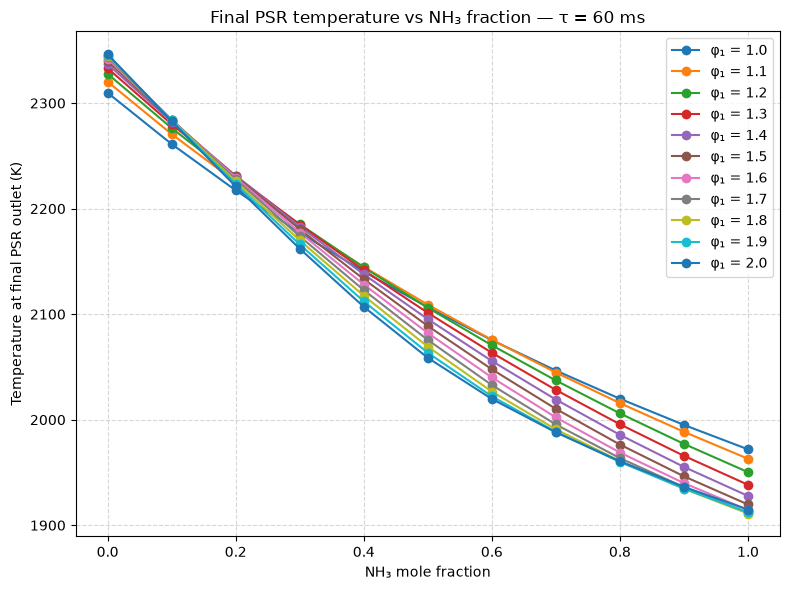

In [57]:
plot_vs_fuel_composition(
    df_tau,
    y_column="T_final_K",
    y_label="Temperature at final PSR outlet (K)",
    title=f"Final PSR temperature vs NH₃ fraction — τ = {TAU_REF_MS:.0f} ms",
    marker="o",
    y_scale="linear"
)


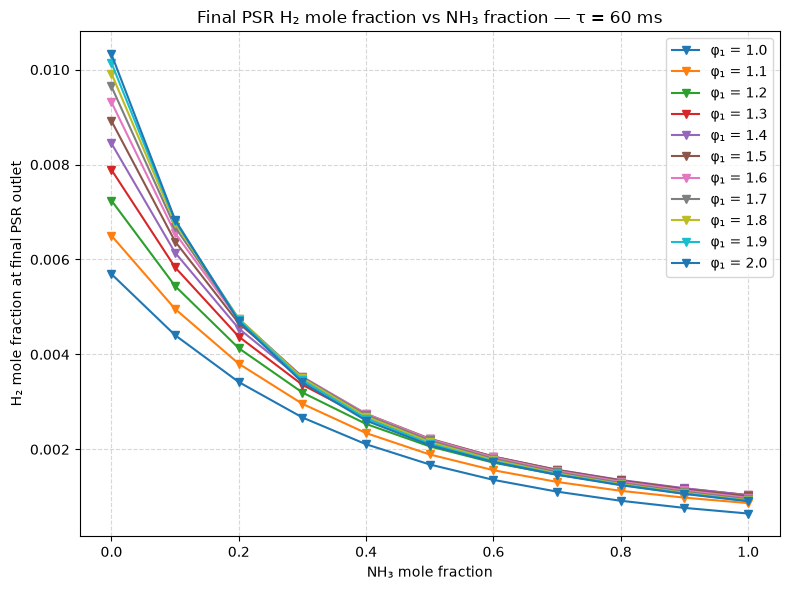

In [58]:
plot_vs_fuel_composition(
    df_tau,
    y_column="X_H2_final",
    y_label="H₂ mole fraction at final PSR outlet",
    title=f"Final PSR H₂ mole fraction vs NH₃ fraction — τ = {TAU_REF_MS:.0f} ms",
    marker="v",
    y_scale="linear"
)


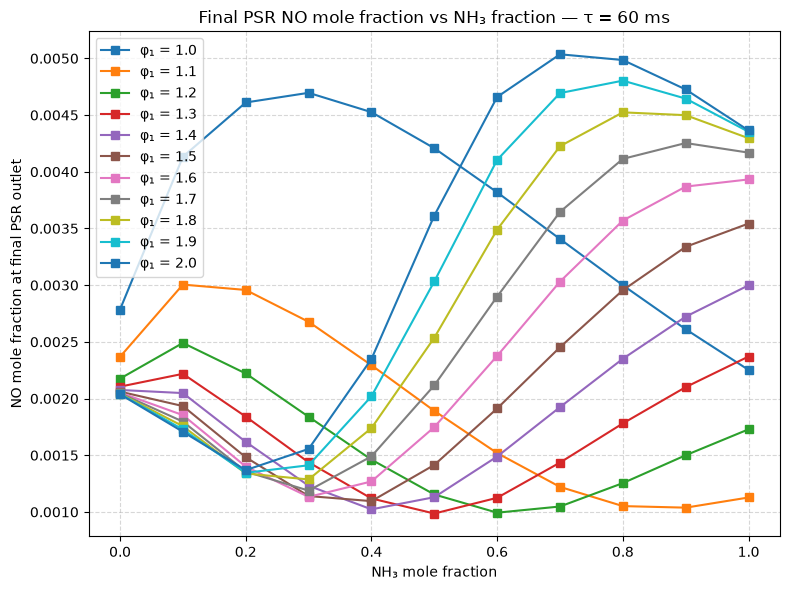

In [59]:
plot_vs_fuel_composition(
    df_tau,
    y_column="X_NO_final",
    y_label="NO mole fraction at final PSR outlet",
    title=f"Final PSR NO mole fraction vs NH₃ fraction — τ = {TAU_REF_MS:.0f} ms",
    marker="s",
    y_scale="linear"
)


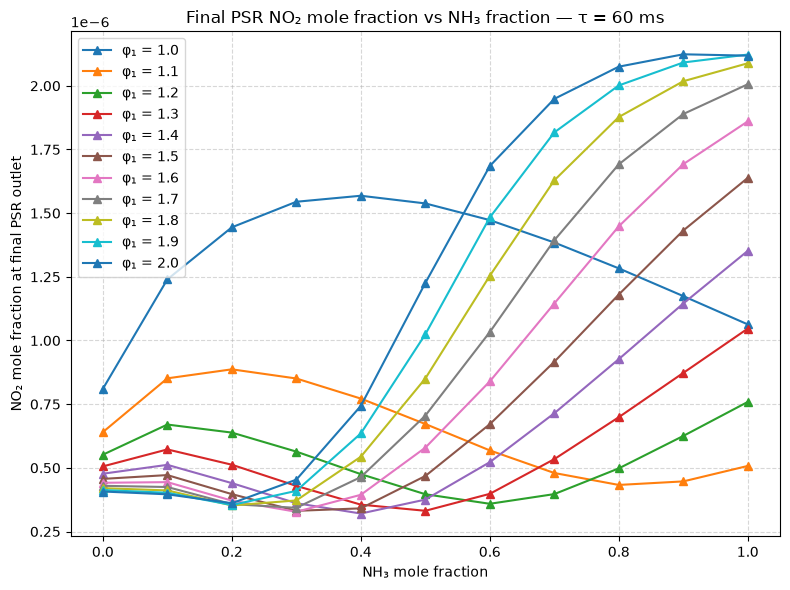

In [60]:
plot_vs_fuel_composition(
    df_tau,
    y_column="X_NO2_final",
    y_label="NO₂ mole fraction at final PSR outlet",
    title=f"Final PSR NO₂ mole fraction vs NH₃ fraction — τ = {TAU_REF_MS:.0f} ms",
    marker="^",
    y_scale="linear"
)


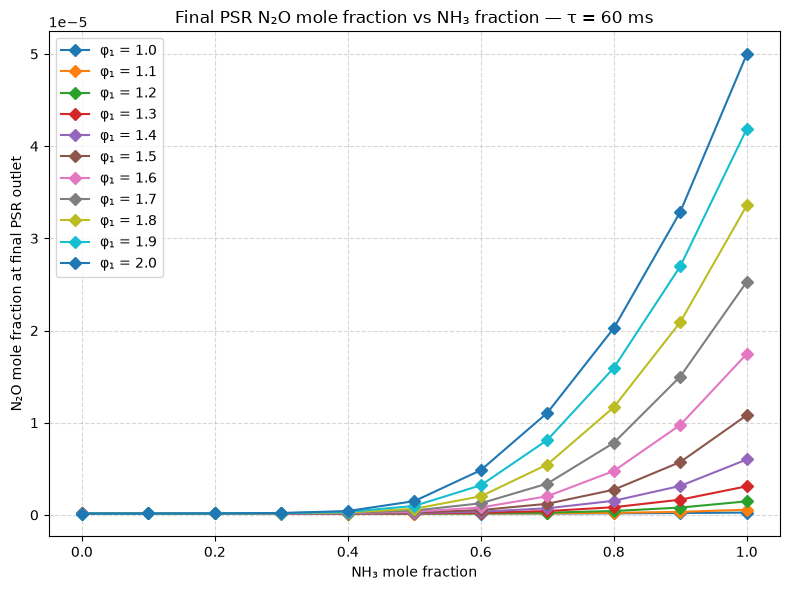

In [61]:
plot_vs_fuel_composition(
    df_tau,
    y_column="X_N2O_final",
    y_label="N₂O mole fraction at final PSR outlet",
    title=f"Final PSR N₂O mole fraction vs NH₃ fraction — τ = {TAU_REF_MS:.0f} ms",
    marker="D",
    y_scale="linear"
)


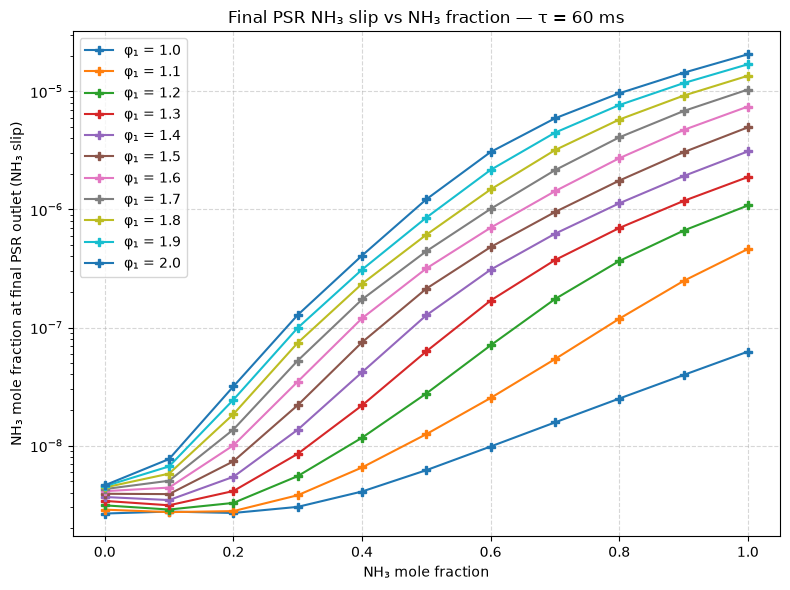

In [62]:
plot_vs_fuel_composition(
    df_tau,
    y_column="X_NH3_final",
    y_label="NH₃ mole fraction at final PSR outlet (NH₃ slip)",
    title=f"Final PSR NH₃ slip vs NH₃ fraction — τ = {TAU_REF_MS:.0f} ms",
    marker="P",
    y_scale="log"
)


### 12.1 Final NOx

NOx is kept as a separate engineering metric:

\[
NO_x = NO + NO_2
\]

N₂O is **not** included in NOx and remains a separate result, matching
the structure of the reference presentation.


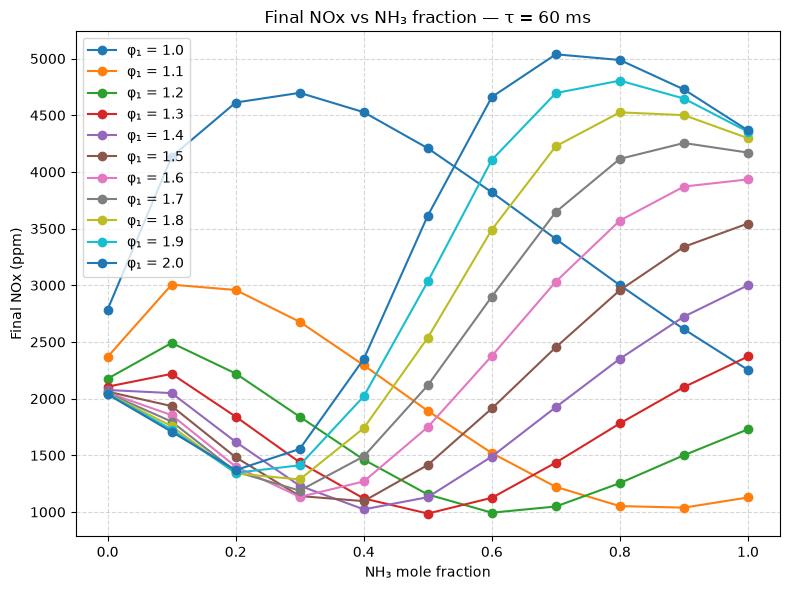

In [63]:
plot_vs_fuel_composition(
    df_tau,
    y_column="NOx_ppm",
    y_label="Final NOx (ppm)",
    title=f"Final NOx vs NH₃ fraction — τ = {TAU_REF_MS:.0f} ms",
    marker="o"
)


## 13. Primary-PSR results

Pages 8–9 of the reference presentation show the corresponding
quantities at the outlet of the **primary PSR**.

These are useful for understanding what enters the secondary-air mixing
stage; they should not be interpreted as final exhaust emissions.


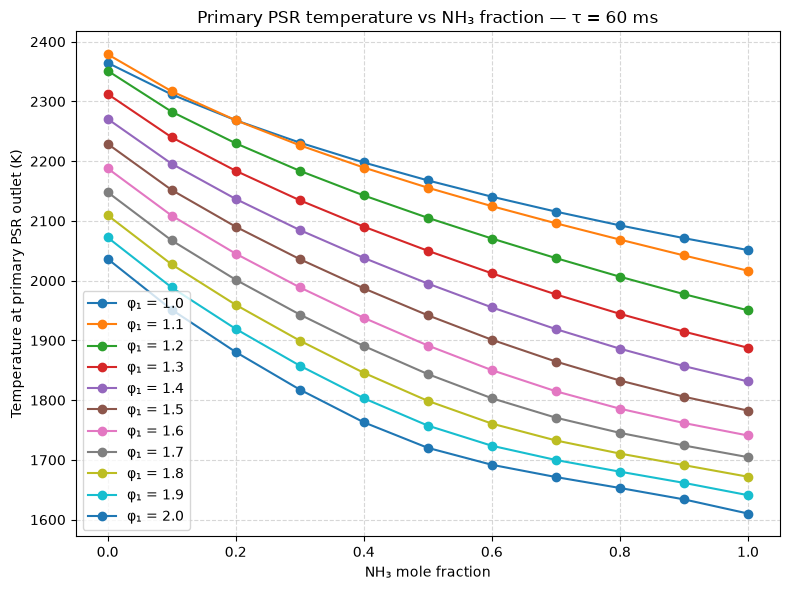

In [64]:
plot_vs_fuel_composition(
    df_tau,
    y_column="T_primary_K",
    y_label="Temperature at primary PSR outlet (K)",
    title=f"Primary PSR temperature vs NH₃ fraction — τ = {TAU_REF_MS:.0f} ms",
    marker="o",
    y_scale="linear"
)


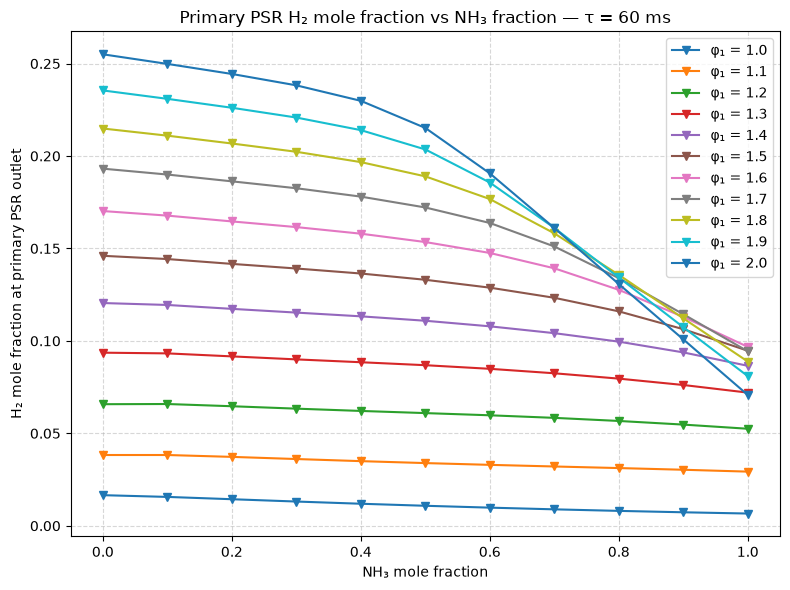

In [65]:
plot_vs_fuel_composition(
    df_tau,
    y_column="X_H2_primary",
    y_label="H₂ mole fraction at primary PSR outlet",
    title=f"Primary PSR H₂ mole fraction vs NH₃ fraction — τ = {TAU_REF_MS:.0f} ms",
    marker="v",
    y_scale="linear"
)


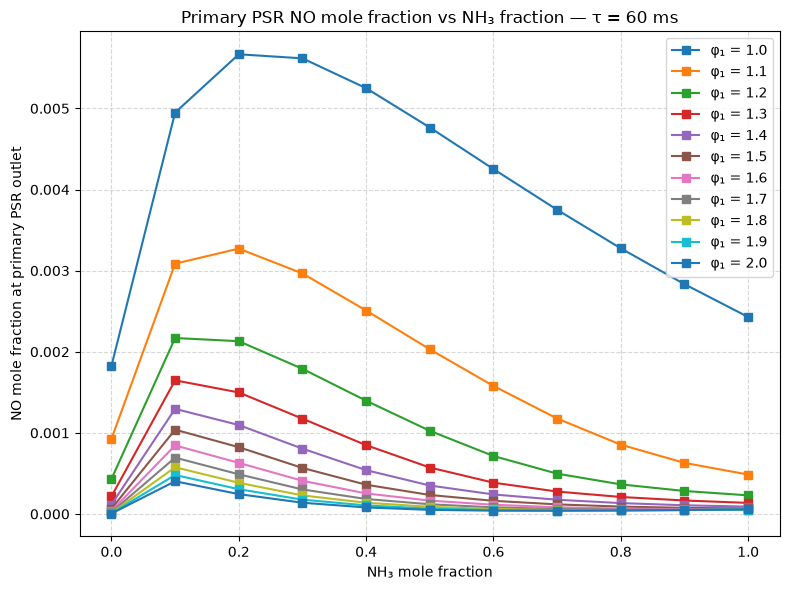

In [ ]:
plot_vs_fuel_composition(
    df_tau,
    y_column="X_NO_primary",
    y_label="NO mole fraction at primary PSR outlet",
    title=f"Primary PSR NO mole fraction vs NH₃ fraction — τ = {TAU_REF_MS:.0f} ms",
    marker="s",
    y_scale="linear"














    
)


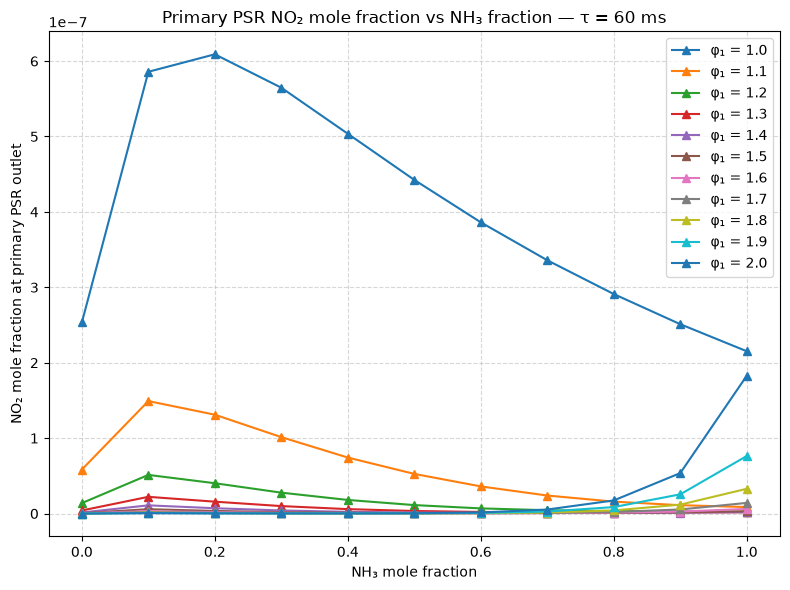

In [67]:
plot_vs_fuel_composition(
    df_tau,
    y_column="X_NO2_primary",
    y_label="NO₂ mole fraction at primary PSR outlet",
    title=f"Primary PSR NO₂ mole fraction vs NH₃ fraction — τ = {TAU_REF_MS:.0f} ms",
    marker="^",
    y_scale="linear"
)


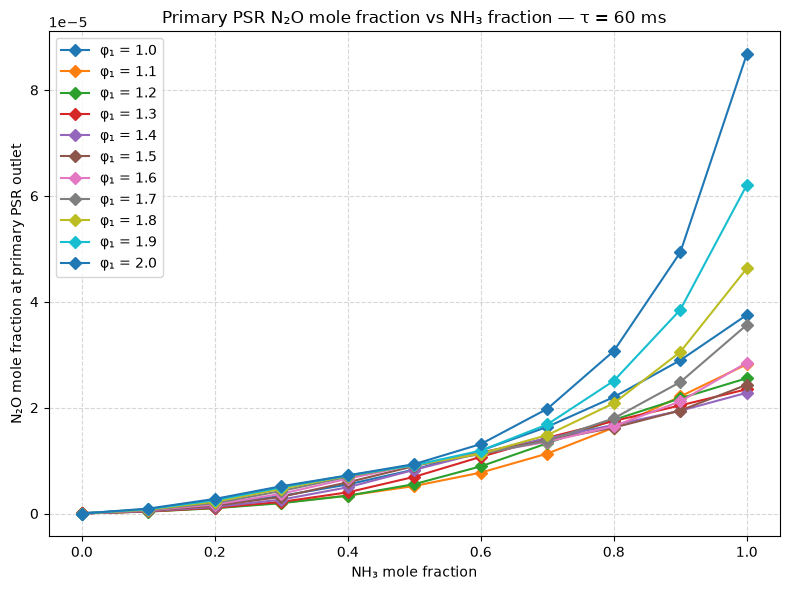

In [68]:
plot_vs_fuel_composition(
    df_tau,
    y_column="X_N2O_primary",
    y_label="N₂O mole fraction at primary PSR outlet",
    title=f"Primary PSR N₂O mole fraction vs NH₃ fraction — τ = {TAU_REF_MS:.0f} ms",
    marker="D",
    y_scale="linear"
)


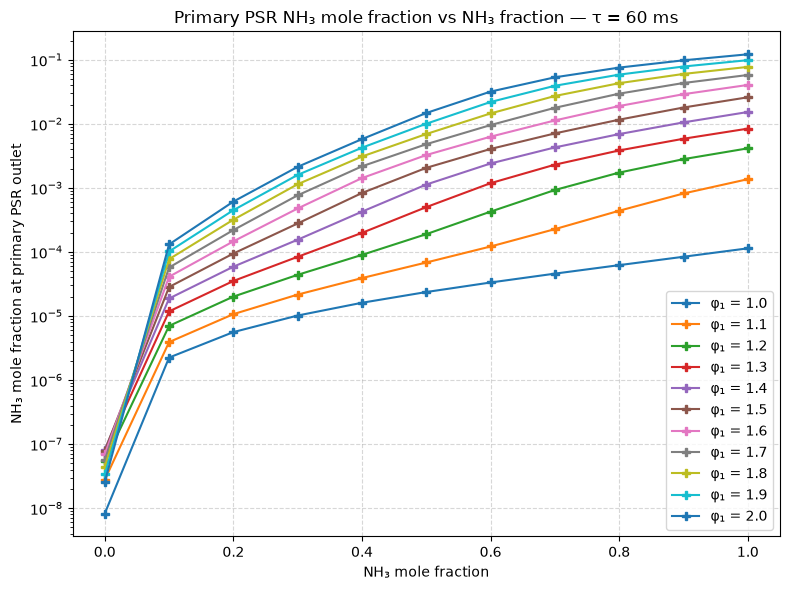

In [69]:
plot_vs_fuel_composition(
    df_tau,
    y_column="X_NH3_primary",
    y_label="NH₃ mole fraction at primary PSR outlet",
    title=f"Primary PSR NH₃ mole fraction vs NH₃ fraction — τ = {TAU_REF_MS:.0f} ms",
    marker="P",
    y_scale="log"
)


## 14. H₂-axis plots

The reference presentation also contains plots with **H₂ mole fraction**
on the x-axis. No additional simulations are required because:

\[
x_{H_2}=1-x_{NH_3}
\]

The same results can therefore be viewed in either fuel-composition
coordinate system.


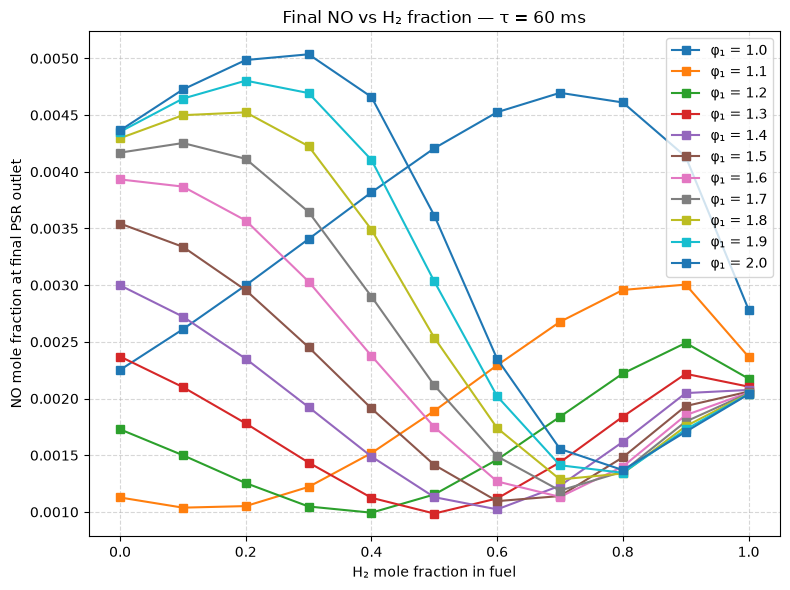

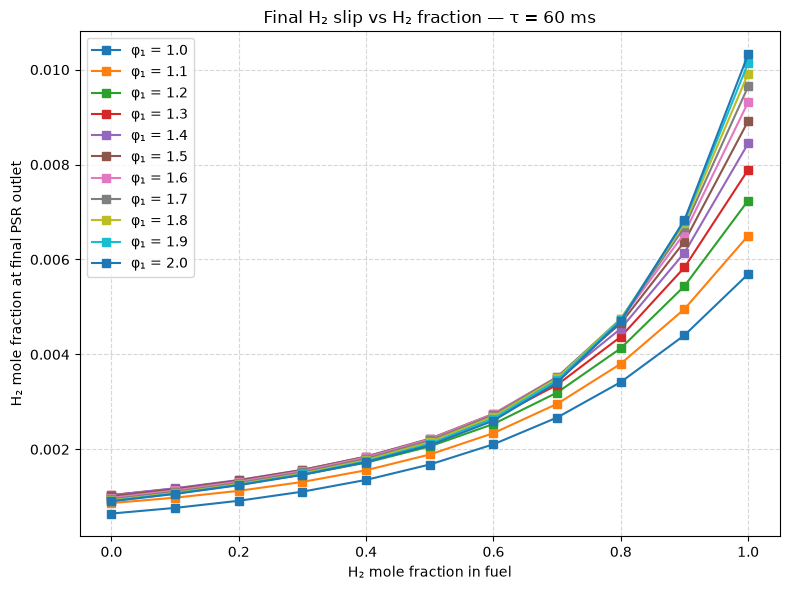

In [70]:
def plot_vs_h2_fraction(
    data,
    y_column,
    y_label,
    title,
    phi_values=PHI_CURVES,
    marker="s"
):
    """Plot one result against H2 fuel mole fraction."""

    fig, ax = plt.subplots(figsize=(8, 6))

    for phi in phi_values:
        sub = data[
            np.isclose(data["Phi_1"], phi)
        ].sort_values("H2_frac")

        if len(sub) == 0:
            continue

        ax.plot(
            sub["H2_frac"],
            sub[y_column],
            marker=marker,
            label=f"φ₁ = {phi:.1f}"
        )

    ax.set_xlabel("H₂ mole fraction in fuel")
    ax.set_ylabel(y_label)
    ax.set_title(title)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()

    plt.tight_layout()
    plt.show()


plot_vs_h2_fraction(
    df_tau,
    "X_NO_final",
    "NO mole fraction at final PSR outlet",
    f"Final NO vs H₂ fraction — τ = {TAU_REF_MS:.0f} ms"
)

plot_vs_h2_fraction(
    df_tau,
    "X_H2_final",
    "H₂ mole fraction at final PSR outlet",
    f"Final H₂ slip vs H₂ fraction — τ = {TAU_REF_MS:.0f} ms"
)


## 15. Residence-time sensitivity

Residence time is an independent variable in the current 605-case sweep,
so it should be analysed directly as well.

Here the fuel composition and primary equivalence ratio are fixed and
residence time is varied from 20 to 100 ms.


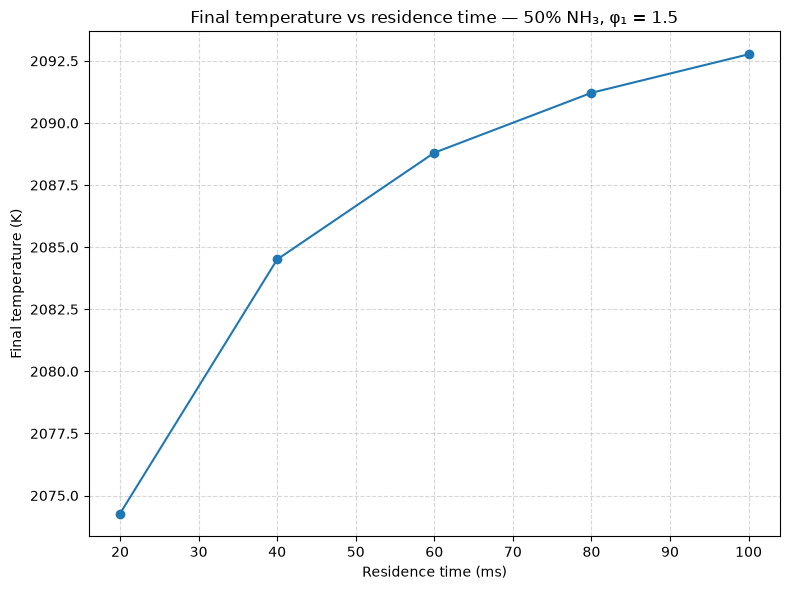

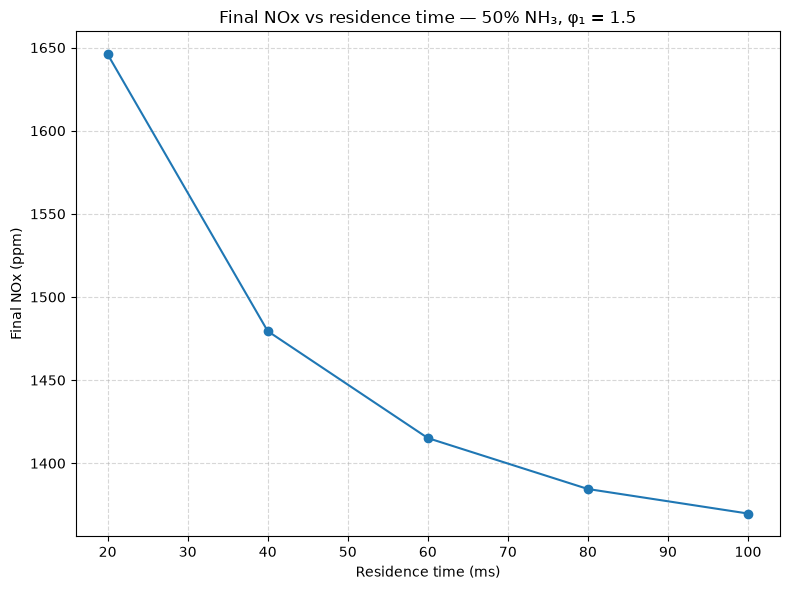

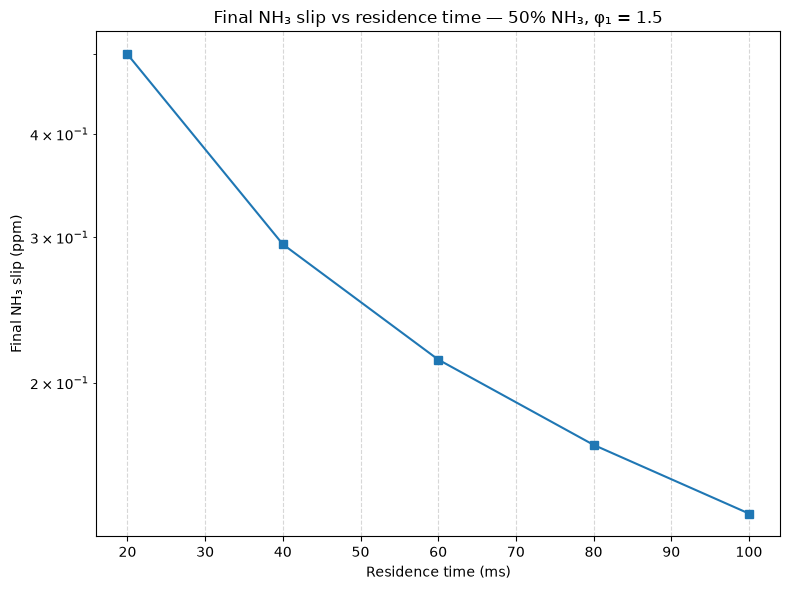

In [71]:
X_NH3_REF = 0.50
PHI_REF = 1.50

df_tau_sensitivity = good[
    np.isclose(good["NH3_frac"], X_NH3_REF)
    & np.isclose(good["Phi_1"], PHI_REF)
].sort_values("Tau_ms")

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(
    df_tau_sensitivity["Tau_ms"],
    df_tau_sensitivity["T_final_K"],
    marker="o"
)
ax.set_xlabel("Residence time (ms)")
ax.set_ylabel("Final temperature (K)")
ax.set_title("Final temperature vs residence time — 50% NH₃, φ₁ = 1.5")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(
    df_tau_sensitivity["Tau_ms"],
    df_tau_sensitivity["NOx_ppm"],
    marker="o"
)
ax.set_xlabel("Residence time (ms)")
ax.set_ylabel("Final NOx (ppm)")
ax.set_title("Final NOx vs residence time — 50% NH₃, φ₁ = 1.5")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(
    df_tau_sensitivity["Tau_ms"],
    df_tau_sensitivity["NH3_slip_ppm"],
    marker="s"
)
ax.set_xlabel("Residence time (ms)")
ax.set_ylabel("Final NH₃ slip (ppm)")
ax.set_title("Final NH₃ slip vs residence time — 50% NH₃, φ₁ = 1.5")
ax.set_yscale("log")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## 16. Contour maps

Because the sweep varies both NH₃ fraction and primary equivalence ratio,
contour maps are useful for identifying regions of high/low temperature,
NOx and NH₃ slip.


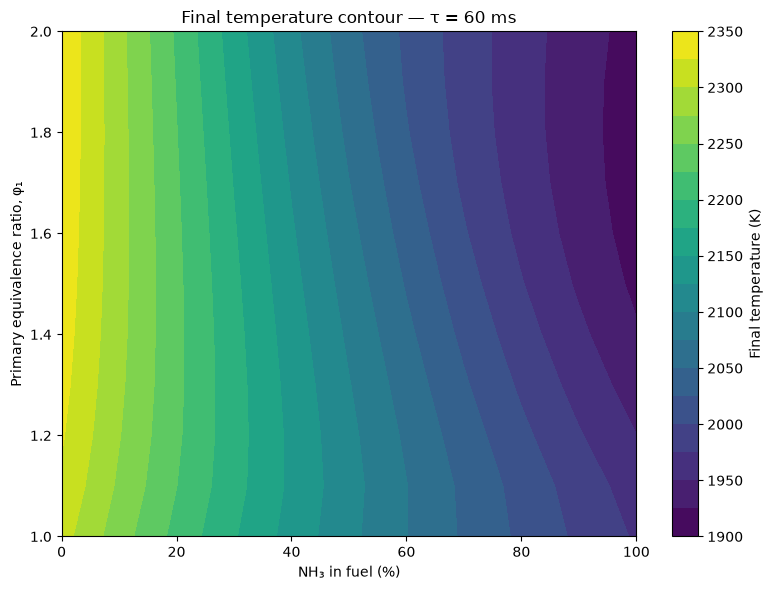

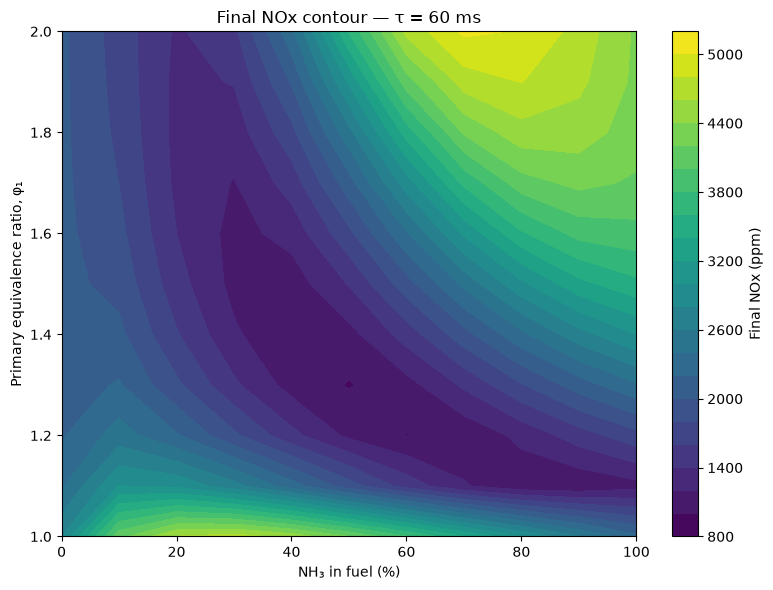

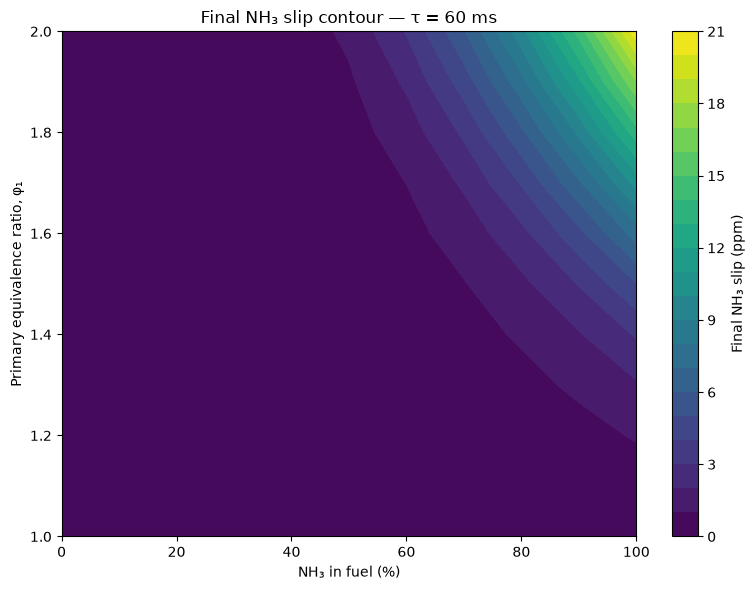

In [72]:
def plot_contour(
    data,
    value_column,
    colorbar_label,
    title,
    tau_ms=TAU_REF_MS
):
    """Create an NH3-fraction vs primary-phi contour map."""

    subset = data[
        np.isclose(data["Tau_ms"], tau_ms)
    ].copy()

    pivot = subset.pivot(
        index="Phi_1",
        columns="NH3_frac",
        values=value_column
    )

    X, Y = np.meshgrid(
        pivot.columns.values * 100,
        pivot.index.values
    )

    fig, ax = plt.subplots(figsize=(8, 6))

    contour = ax.contourf(
        X,
        Y,
        pivot.values,
        levels=20
    )

    fig.colorbar(
        contour,
        ax=ax,
        label=colorbar_label
    )

    ax.set_xlabel("NH₃ in fuel (%)")
    ax.set_ylabel("Primary equivalence ratio, φ₁")
    ax.set_title(f"{title} — τ = {tau_ms:.0f} ms")

    plt.tight_layout()
    plt.show()


plot_contour(
    good,
    "T_final_K",
    "Final temperature (K)",
    "Final temperature contour"
)

plot_contour(
    good,
    "NOx_ppm",
    "Final NOx (ppm)",
    "Final NOx contour"
)

plot_contour(
    good,
    "NH3_slip_ppm",
    "Final NH₃ slip (ppm)",
    "Final NH₃ slip contour"
)


## 17. Save the expanded results

The CSV now contains the original operating-condition information plus
the outlet composition of **both PSRs**.

This means the plots can be regenerated later without rerunning the
605 simulations.


In [73]:
df.to_csv(
    "results/staged_combustion_results_full.csv",
    index=False
)

print("Saved: staged_combustion_results_full.csv")
print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())


Saved: staged_combustion_results_full.csv
Rows: 605
Columns: 38


,NH3_frac,H2_frac,Phi_1,Phi_overall,Tau_ms,Air_stoic,Air_primary,Air_secondary,Air_total,T_primary_K,...,NO2_ppm,NOx_ppm,N2O_ppm,NH3_slip_ppm,H2_slip_ppm,NH3_conversion,H2_conversion,Primary_integration_s,Secondary_integration_s,Status
0,0.0,1.0,1.0,0.9,20.0,2.38,2.38,0.264444,2.644444,2340.392165,...,0.516376,1794.157409,0.183836,0.002021,5828.607091,NaN,97.875797,1.12,0.4,Converged
1,0.0,1.0,1.0,0.9,40.0,2.38,2.38,0.264444,2.644444,2358.052361,...,0.711862,2449.365061,0.186370,0.002448,5718.299166,NaN,97.915998,3.80,1.0,Converged
2,0.0,1.0,1.0,0.9,60.0,2.38,2.38,0.264444,2.644444,2364.660288,...,0.810235,2786.052271,0.187803,0.002656,5692.744819,NaN,97.925311,6.00,1.8,Converged
3,0.0,1.0,1.0,0.9,80.0,2.38,2.38,0.264444,2.644444,2368.121448,...,0.869139,2989.804100,0.188731,0.002779,5682.860710,NaN,97.928913,6.88,2.0,Converged
4,0.0,1.0,1.0,0.9,100.0,2.38,2.38,0.264444,2.644444,2370.251135,...,0.908249,3125.961512,0.189377,0.002861,5678.003418,NaN,97.930683,4.80,2.2,Converged
